### What each weight in a relu layer does

Built up one step at a time, each claim followed by a cell that checks it on real numbers.


In [57]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from pytest import approx
from torch import Tensor, nn

torch.manual_seed(0)


def n_params(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters())


def show(x: Tensor, y: Tensor) -> None:
    print("x:", " ".join(f"{v:3.0f}" for v in x.squeeze(-1)))
    print("y:", " ".join(f"{v:3.0f}" for v in y.squeeze(-1)))

**1. Without relu, stacked layers collapse.** A linear layer is `x @ W.T + b`, and a linear layer of a linear layer is still one:

```
down(up(x)) = (x @ W1.T + b1) @ W2.T + b2
            = x @ (W2 @ W1).T + (W2 @ b1 + b2)
```

So we can build the single merged layer by hand.


In [58]:
def merged_linear(up: nn.Linear, down: nn.Linear) -> nn.Linear:
    merged = nn.Linear(up.in_features, down.out_features)
    with torch.no_grad():
        merged.weight.copy_(down.weight @ up.weight)  # [out, in]
        merged.bias.copy_(down.weight @ up.bias + down.bias)  # [out]
    return merged


N, E, H = 5, 8, 32
up = nn.Linear(E, H)
down = nn.Linear(H, E)
merged = merged_linear(up, down)
x = torch.randn(N, E)
with torch.no_grad():
    print((merged(x) - down(up(x))).abs().max())
    assert merged(x) == approx(down(up(x)), abs=1e-5)

tensor(1.2666e-07)


The E → H → E stack is just an E → E layer. Depth added parameters but no expressive power.


In [59]:
print("stacked:", n_params(up) + n_params(down))  # (E*H + H) + (H*E + E)
print("merged: ", n_params(merged))  # E*E + E
assert n_params(up) + n_params(down) == (E * H + H) + (H * E + E) == 552
assert n_params(merged) == E * E + E == 72

stacked: 552
merged:  72


**2. Relu between the layers breaks the collapse.** Relu zeroes the negative entries of `up(x)`, so the products no longer multiply out into one weight.


In [60]:
def relu_stack(x: Tensor) -> Tensor:
    return down(F.relu(up(x)))


with torch.no_grad():
    print((relu_stack(x) - merged(x)).abs().max())
    assert relu_stack(x) != approx(merged(x), abs=1e-3)

tensor(0.6941)


That only shows this particular merge fails. To show _no_ linear layer works, however big: any linear f has

```
f(x) + f(y) == f(0) + f(x + y)      # both sides are (x + y) @ W.T + 2 * b
```

The merged layer passes this, the relu stack doesn't.


In [61]:
y = torch.randn(N, E)
zero = torch.zeros(N, E)
with torch.no_grad():
    lin_gap = (merged(x) + merged(y)) - (merged(zero) + merged(x + y))
    relu_gap = (relu_stack(x) + relu_stack(y)) - (relu_stack(zero) + relu_stack(x + y))
print("linear gap:", lin_gap.abs().max().item())
print("relu gap:  ", relu_gap.abs().max().item())
assert lin_gap == approx(0, abs=1e-5)
assert relu_gap != approx(0, abs=1e-3)

linear gap: 1.1920928955078125e-07
relu gap:   0.2824852168560028


**3. Each relu neuron is a ramp.** With one input and one output, neuron i does

```
w_down · relu(w_up · x + b_up)
```

0 on one side of a threshold, a straight line on the other. The output is the sum of these ramps plus `b_down`.

**The sign of the `up` weight sets which side fires**: positive fires above the threshold, negative below. Its size scales the ramp, relu(3x) climbs three times as fast as relu(x).


In [62]:
x = torch.arange(-3.0, 4.0)
print("relu(x):  ", F.relu(x))
print("relu(-x): ", F.relu(-x))
print("relu(3x): ", F.relu(3 * x))
assert torch.equal(F.relu(3 * x), 3 * F.relu(x))

relu(x):   tensor([0., 0., 0., 0., 1., 2., 3.])
relu(-x):  tensor([3., 2., 1., -0., 0., 0., 0.])
relu(3x):  tensor([0., 0., 0., 0., 3., 6., 9.])


w_up = 1 and −1 give the two halves, and `down` adds them: |x| = relu(x) + relu(−x).


In [63]:
up = nn.Linear(1, 2, bias=False)
down = nn.Linear(2, 1, bias=False)
with torch.no_grad():
    up.weight.copy_(torch.tensor([[1.0], [-1.0]]))  # [2, 1]
    down.weight.copy_(torch.tensor([[1.0, 1.0]]))  # [1, 2]
x = torch.linspace(-3, 3, steps=7).unsqueeze(-1)  # [7, 1]
with torch.no_grad():
    no_relu = down(up(x))
    with_relu = down(F.relu(up(x)))
show(x, no_relu)  # x - x, the halves cancel
show(x, with_relu)  # each half keeps its positive side
assert torch.equal(no_relu, torch.zeros_like(x))
assert torch.equal(with_relu, x.abs())

x:  -3  -2  -1   0   1   2   3
y:   0   0   0   0   0   0   0
x:  -3  -2  -1   0   1   2   3
y:   3   2   1   0   1   2   3


And no linear layer gives |x|: every linear f has f(1) + f(−1) == 2 · f(0), but |1| + |−1| = 2 while 2 · |0| = 0.

**4. The `up` bias sets the threshold.** The neuron turns on where w_up · x + b_up = 0, at x = −b_up / w_up. With w_up = 1 that's x = −b_up: bias −2 keeps the neuron off up to x = 2, bias 2 has it on from x = −1.


In [64]:
biases = torch.tensor([-2.0, -1.0, 0.0, 1.0, 2.0])
slope_changes = torch.tensor([2.0, -2.0, 2.0, -2.0, 1.0])
up = nn.Linear(1, 5)
down = nn.Linear(5, 1, bias=False)
with torch.no_grad():
    up.weight.copy_(torch.ones(5, 1))  # [5, 1]
    up.bias.copy_(biases)  # [5]
    down.weight.copy_(slope_changes.unsqueeze(0))  # [1, 5]

x = torch.arange(-2.0, 3.0).unsqueeze(-1)  # [5, 1], x = -2 .. 2
with torch.no_grad():
    hidden = F.relu(up(x))  # [5, 5], row per x, column per bias -2 .. 2
print(hidden)
assert torch.equal(
    hidden,
    torch.tensor(
        [
            [0.0, 0.0, 0.0, 0.0, 0.0],  # x = -2, all off
            [0.0, 0.0, 0.0, 0.0, 1.0],  # x = -1, bias 2 on
            [0.0, 0.0, 0.0, 1.0, 2.0],  # x = 0, bias 1 and up on
            [0.0, 0.0, 1.0, 2.0, 3.0],  # x = 1, bias 0 and up on
            [0.0, 1.0, 2.0, 3.0, 4.0],  # x = 2, bias -1 and up on, bias -2 still off
        ]
    ),
)

tensor([[0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 1.],
        [0., 0., 0., 1., 2.],
        [0., 0., 1., 2., 3.],
        [0., 1., 2., 3., 4.]])


**5. The `down` weight is the slope change at that neuron's bend.** Once a neuron turns on it adds w_up · w_down to the slope from there on, so the slope in any region is the sum over the neurons that are on. `down` mixes the columns with weights 2, −2, 2, −2, 1:

```
x = -2:  0
x = -1:  1                      bias 2 on, slope +1
x =  0:  -2 + 2 = 0             bias 1 adds -2, slope -1
x =  1:  2 - 4 + 3 = 1          bias 0 adds +2, slope +1
x =  2:  -2 + 4 - 6 + 4 = 0     bias -1 adds -2, slope -1
```


In [65]:
with torch.no_grad():
    out = down(hidden)  # [5, 1]
show(x, out)
assert torch.equal(out, torch.tensor([[0.0], [1.0], [0.0], [1.0], [0.0]]))

x:  -2  -1   0   1   2
y:   0   1   0   1   0


Each neuron turning on flips the slope, so the output zigzags, a bend at each threshold. Without relu every neuron is on everywhere and they sum to one line:

```
2(x - 2) - 2(x - 1) + 2x - 2(x + 1) + (x + 2) == x - 2
```


x:  -2  -1   0   1   2
y:  -4  -3  -2  -1   0


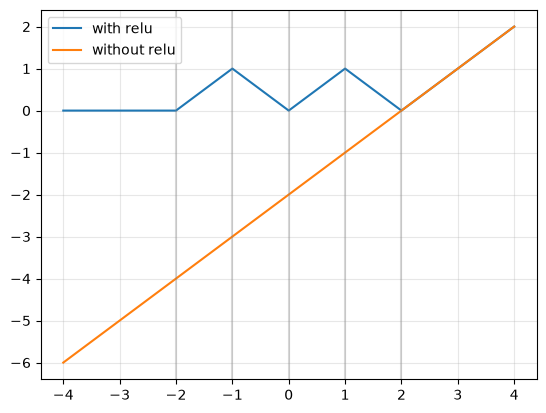

In [66]:
with torch.no_grad():
    no_relu = down(up(x))
show(x, no_relu)
assert torch.equal(no_relu, x - 2)

xs = torch.linspace(-4, 4, 161).unsqueeze(-1)
with torch.no_grad():
    plt.plot(xs, down(F.relu(up(xs))), label="with relu")
    plt.plot(xs, down(up(xs)), label="without relu")
for b in biases:
    plt.axvline(-b.item(), color="gray", alpha=0.3)  # thresholds
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**6. The `down` bias shifts the whole output** up or down.


In [67]:
shifted = nn.Linear(5, 1)
with torch.no_grad():
    shifted.weight.copy_(down.weight)
    shifted.bias.fill_(10.0)
    show(x, shifted(hidden))
    assert torch.equal(shifted(hidden), down(hidden) + 10)

x:  -2  -1   0   1   2
y:  10  11  10  11  10


**7. A by-hand example.** up weight −1, 1, 1, up bias 0, 0, −2 and down weight 1, 1, 2 give the neurons relu(−x), relu(x) and 2 · relu(x − 2):

- x < 0, only relu(−x) is on, slope −1
- 0 to 2, only relu(x) is on, slope +1
- x > 2, relu(x) and 2 · relu(x − 2) are on, slope 1 + 2 = 3

```
x       −2  −1   0   1   2   3   4   5
output   2   1   0   1   2   5   8  11
```


x:  -2  -1   0   1   2   3   4   5
y:   2   1   0   1   2   5   8  11


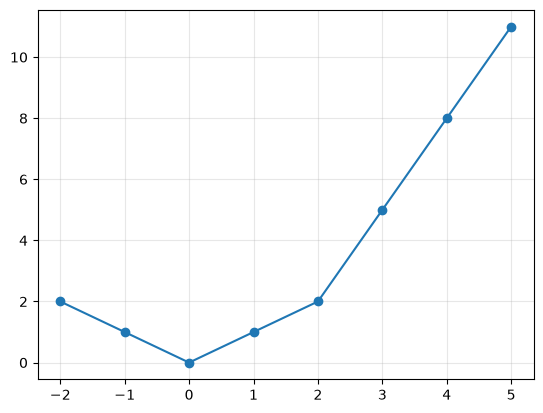

In [68]:
up = nn.Linear(1, 3)
down = nn.Linear(3, 1, bias=False)
with torch.no_grad():
    up.weight.copy_(torch.tensor([[-1.0], [1.0], [1.0]]))  # [3, 1]
    up.bias.copy_(torch.tensor([0.0, 0.0, -2.0]))  # [3]
    down.weight.copy_(torch.tensor([[1.0, 1.0, 2.0]]))  # [1, 3]

x = torch.arange(-2.0, 6.0).unsqueeze(-1)  # [8, 1], x = -2 .. 5
with torch.no_grad():
    y = down(F.relu(up(x)))  # [8, 1]
show(x, y)
assert torch.equal(y.squeeze(-1), torch.tensor([2.0, 1, 0, 1, 2, 5, 8, 11]))
plt.plot(x, y, marker="o")
plt.grid(alpha=0.3)
plt.show()

**8. In the model, x is a vector.** Each neuron's `up` row is then a direction, and the threshold w_up · x + b_up = 0 becomes a flat boundary (a hyperplane) that splits the input space. The neuron fires on one side of it. Below, one neuron in 2-D with w_up = [1, 1], b_up = −1 fires above the line x0 + x1 = 1.


In [69]:
neuron = nn.Linear(2, 1)
with torch.no_grad():
    neuron.weight.copy_(torch.tensor([[1.0, 1.0]]))  # [1, 2]
    neuron.bias.fill_(-1.0)
points = torch.tensor(
    [[0.0, 0.0], [1.0, 0.0], [0.5, 0.5], [1.0, 1.0], [2.0, -0.5], [-1.0, 3.0]]
)  # [6, 2]
with torch.no_grad():
    fires = F.relu(neuron(points)).squeeze(-1)  # [6]
for p, f in zip(points.tolist(), fires.tolist()):
    print(p, "sum", sum(p), "->", f)
assert torch.equal(fires > 0, points.sum(-1) > 1)

[0.0, 0.0] sum 0.0 -> 0.0
[1.0, 0.0] sum 1.0 -> 0.0
[0.5, 0.5] sum 1.0 -> 0.0
[1.0, 1.0] sum 2.0 -> 1.0
[2.0, -0.5] sum 1.5 -> 0.5
[-1.0, 3.0] sum 2.0 -> 1.0


The feed-forward layer has 4E of these boundaries, and that's how it picks out different input patterns.


**9. Enough bends fit any curve.** Without relu, two layers only ever give a straight line, however wide. With relu each hidden neuron adds one bend (step 5), so H neurons give at most H bends, and more bends make shorter straight pieces that hug the curve closer. Below, `up` / `down` are trained to fit sin(x) on [−π, π] at widths 8, 16 and 32. The gray lines mark each neuron's bend, x = −b_up / w_up, inside the range.

Two catches: it's always straight pieces, never a true curve, and past the last bend it carries on as a straight line, so it only fits the range it was trained on.


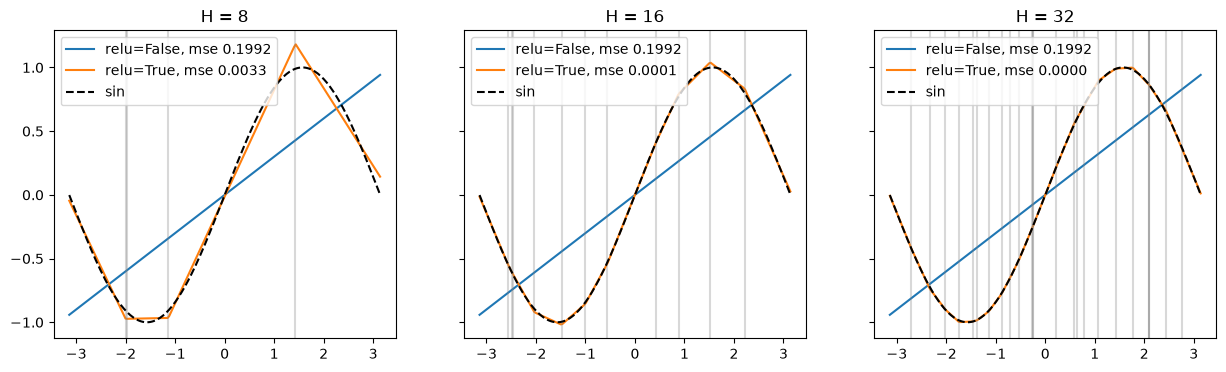

H= 8 relu=False  mse=0.19925
H= 8 relu=True   mse=0.00332
H=16 relu=False  mse=0.19925
H=16 relu=True   mse=0.00012
H=32 relu=False  mse=0.19925
H=32 relu=True   mse=0.00002


In [70]:
x = torch.linspace(-3.14, 3.14, 200).unsqueeze(-1)  # [200, 1]
y = torch.sin(x)
widths = [8, 16, 32]
fig, axes = plt.subplots(1, len(widths), figsize=(15, 4), sharey=True)
mse = {}
for H, ax in zip(widths, axes):
    for relu in [False, True]:
        torch.manual_seed(0)
        up, down = nn.Linear(1, H), nn.Linear(H, 1)
        opt = torch.optim.Adam([*up.parameters(), *down.parameters()], lr=1e-2)
        for _ in range(3000):
            h = F.relu(up(x)) if relu else up(x)
            loss = F.mse_loss(down(h), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
        mse[H, relu] = loss.item()
        ax.plot(x, down(h).detach(), label=f"relu={relu}, mse {loss.item():.4f}")
    with torch.no_grad():
        bends = -up.bias / up.weight.squeeze(-1)  # [H], from the relu run
    for b in bends[bends.abs() < 3.14]:
        ax.axvline(b.item(), color="gray", alpha=0.3)
    ax.plot(x, y, "k--", label="sin")
    ax.set_title(f"H = {H}")
    ax.legend()
plt.show()
for (H, relu), v in mse.items():
    print(f"H={H:2d} relu={relu!s:5}  mse={v:.5f}")

In [71]:
# without relu the best fit is the same straight line at every width
assert mse[16, False] == approx(mse[8, False], rel=1e-3)
assert mse[32, False] == approx(mse[8, False], rel=1e-3)
# with relu more bends mean shorter pieces and a closer fit
assert mse[8, True] > mse[16, True] > mse[32, True]
assert mse[8, True] < mse[8, False] / 10